# RFM segmentation and customer lifetime value

Customer-level analysis of delivered orders, January 2017 – August 2018.
Source: `mart.fact_orders` and `mart.dim_date`. Snapshot date: 2018-09-01.
Frequency counts distinct purchase days (same-day orders are one occasion, see BQ2).

In [2]:
#setup and connection
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine, URL

PROJECT_DIR = Path.cwd().parent          # the notebook runs from notebooks/
FIG_DIR = PROJECT_DIR / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

load_dotenv(PROJECT_DIR / ".env")
engine = create_engine(URL.create(
    drivername="postgresql+psycopg",
    host=os.getenv("PGHOST"),
    port=int(os.getenv("PGPORT")),
    username=os.getenv("PGUSER"),
    password=os.getenv("PGPASSWORD"),
    database=os.getenv("PGDATABASE"),
))

pd.set_option("display.float_format", "{:,.2f}".format)
print(PROJECT_DIR)

d:\portfolio\olist-commercial-analytics


In [ ]:
#load one row per customer
query = """
SELECT
    o.customer_unique_id,
    MIN(d.full_date)            AS first_date,
    MAX(d.full_date)            AS last_date,
    COUNT(*)                    AS orders,
    COUNT(DISTINCT d.full_date) AS purchase_days,
    SUM(o.order_gmv)            AS gmv
FROM mart.fact_orders o
JOIN mart.dim_date d ON d.date_key = o.purchase_date_key
WHERE o.is_delivered
  AND d.in_analysis_period
GROUP BY o.customer_unique_id
"""
customers = pd.read_sql(query, engine, parse_dates=["first_date", "last_date"])
customers["gmv"] = customers["gmv"].astype(float)   # NUMERIC -> Decimal -> float
print(customers.shape)
customers.head()

(93104, 6)


,customer_unique_id,first_date,last_date,orders,purchase_days,gmv
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10,2018-05-10,1,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07,2018-05-07,1,1,18.90
2,0000f46a3911fa3c0805444483337064,2017-03-10,2017-03-10,1,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12,2017-10-12,1,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14,2017-11-14,1,1,180.00


In [4]:
#reconcile with the SQL results (professional standard: prove the data matches before analysing it)
checks = pd.DataFrame({
    "check":    ["customers", "orders", "GMV", "returned on a later date"],
    "expected": [93_104, 96_211, 13_181_027.13, 2_005],
    "actual":   [len(customers),
                 customers["orders"].sum(),
                 round(customers["gmv"].sum(), 2),
                 (customers["purchase_days"] >= 2).sum()],
})
checks["result"] = np.where((checks["expected"] - checks["actual"]).abs() < 0.01, "PASS", "FAIL")
checks

,check,expected,actual,result
0,customers,"93,104.00","93,104.00",PASS
1,orders,"96,211.00","96,211.00",PASS
2,GMV,"13,181,027.13","13,181,027.13",PASS
3,returned on a later date,"2,005.00","2,005.00",PASS


In [5]:
#RFM inputs, and the frequency problem
SNAPSHOT = pd.Timestamp("2018-09-01")

customers["recency_days"] = (SNAPSHOT - customers["last_date"]).dt.days
customers["frequency"]    = customers["purchase_days"]
customers["monetary"]     = customers["gmv"]

customers["frequency"].value_counts().sort_index()

frequency
1     91099
2      1855
3       119
4        17
5         6
6         5
7         2
15        1
Name: count, dtype: int64

In [7]:
#scores and segments
# R and M: quintiles (5 = best). F: binary, because frequency has no spread
customers["R"] = pd.qcut(customers["recency_days"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
customers["M"] = pd.qcut(customers["monetary"],     5, labels=[1, 2, 3, 4, 5]).astype(int)
customers["F"] = np.where(customers["frequency"] >= 2, 2, 1)

rules = [
    (customers["F"] == 2) & (customers["R"] >= 4),
    (customers["F"] == 2) & (customers["R"] <= 3),
    (customers["F"] == 1) & (customers["M"] >= 4) & (customers["R"] >= 4),
    (customers["F"] == 1) & (customers["M"] >= 4) & (customers["R"] <= 3),
    (customers["F"] == 1) & (customers["M"] <= 3) & (customers["R"] >= 4),
    (customers["F"] == 1) & (customers["M"] <= 3) & (customers["R"] <= 3),
]
segments = [
    "1. Repeat, recent",
    "2. Repeat, lapsing",
    "3. One-time, high value, recent",
    "4. One-time, high value, lapsed",
    "5. One-time, low value, recent",
    "6. One-time, low value, lapsed",
]
customers["segment"] = np.select(rules, segments, default="Unassigned")

customers["segment"].value_counts().sort_index()

segment
1. Repeat, recent                   1056
2. Repeat, lapsing                   949
3. One-time, high value, recent    14499
4. One-time, high value, lapsed    20954
5. One-time, low value, recent     21764
6. One-time, low value, lapsed     33882
Name: count, dtype: int64

In [8]:
#segment summary
seg = (customers
       .groupby("segment")
       .agg(customers=("customer_unique_id", "count"),
            gmv=("gmv", "sum"),
            avg_gmv=("gmv", "mean"),
            avg_recency_days=("recency_days", "mean"))
       .assign(customer_share_pct=lambda x: 100 * x["customers"] / x["customers"].sum(),
               gmv_share_pct=lambda x: 100 * x["gmv"] / x["gmv"].sum()))
seg

,customers,gmv,avg_gmv,avg_recency_days,customer_share_pct,gmv_share_pct
segment,,,,,,
"1. Repeat, recent",1056,"291,615.61",276.15,89.26,1.13,2.21
"2. Repeat, lapsing",949,"252,673.71",266.25,309.46,1.02,1.92
"3. One-time, high value, recent",14499,"3,887,309.42",268.11,94.16,15.57,29.49
"4. One-time, high value, lapsed",20954,"5,640,212.55",269.17,336.52,22.51,42.79
"5. One-time, low value, recent",21764,"1,212,792.21",55.72,92.14,23.38,9.20
"6. One-time, low value, lapsed",33882,"1,896,423.63",55.97,338.36,36.39,14.39


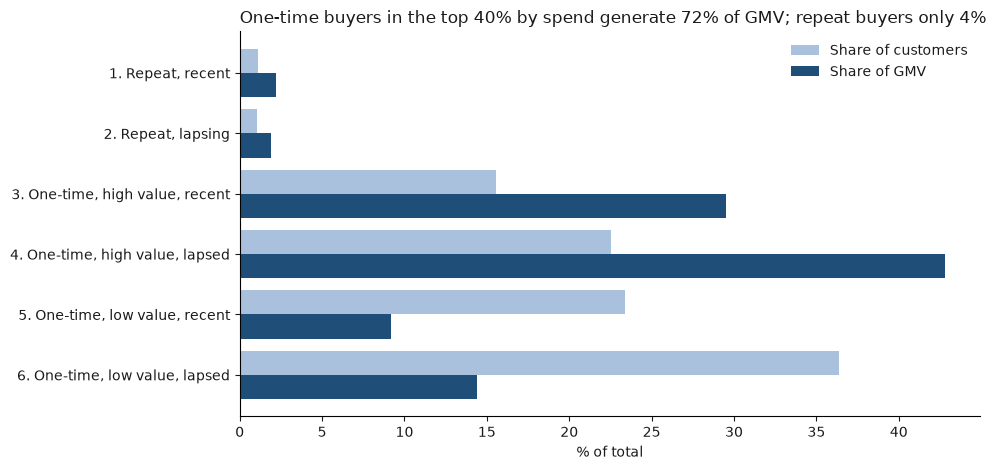

In [18]:
#chart (light background, dark text)
TEXT = "#1a1a1a"
fig, ax = plt.subplots(figsize=(10, 4.8), facecolor="white")
ax.set_facecolor("white")

y = np.arange(len(seg))
ax.barh(y - 0.2, seg["customer_share_pct"], height=0.4, color="#a9c1dd", label="Share of customers")
ax.barh(y + 0.2, seg["gmv_share_pct"],      height=0.4, color="#1f4e79", label="Share of GMV")

ax.set_yticks(y, seg.index)
ax.invert_yaxis()
ax.set_xlabel("% of total", color=TEXT)
ax.set_title("One-time buyers in the top 40% by spend generate 72% of GMV; repeat buyers only 4%",
             color=TEXT, loc="left")
ax.tick_params(colors=TEXT)
ax.legend(frameon=False, labelcolor=TEXT)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
fig.savefig(FIG_DIR / "rfm_segments.png", dpi=150, facecolor="white")
plt.show()

## Customer lifetime value (empirical, by window)

Cumulative GMV per customer within N days of the first purchase, for customers
whose full window ends by 2018-08-31. Uplift compares each window with the
first-day GMV of the same customers. Revenue CLV: no margin data available.

In [19]:
#load orders and attach each customer’s first date
orders = pd.read_sql("""
    SELECT o.customer_unique_id, d.full_date AS purchase_date, o.order_gmv
    FROM mart.fact_orders o
    JOIN mart.dim_date d ON d.date_key = o.purchase_date_key
    WHERE o.is_delivered
      AND d.in_analysis_period
""", engine, parse_dates=["purchase_date"])
orders["order_gmv"] = orders["order_gmv"].astype(float)

orders = orders.merge(customers[["customer_unique_id", "first_date"]], on="customer_unique_id")
orders["days_since_first"] = (orders["purchase_date"] - orders["first_date"]).dt.days

print(len(orders), round(orders["order_gmv"].sum(), 2))

96211 13181027.13


In [20]:
#CLV by window
CUTOFF = pd.Timestamp("2018-08-31")
rows = []

for window in [0, 30, 90, 180, 365]:
    eligible = customers.loc[
        customers["first_date"] + pd.Timedelta(days=window) <= CUTOFF, "customer_unique_id"]
    their_orders = orders[orders["customer_unique_id"].isin(eligible)]

    first_day_gmv = their_orders.loc[their_orders["days_since_first"] == 0, "order_gmv"].sum()
    window_gmv    = their_orders.loc[their_orders["days_since_first"] <= window, "order_gmv"].sum()
    window_orders = (their_orders["days_since_first"] <= window).sum()

    rows.append({
        "window_days":           window,
        "eligible_customers":    len(eligible),
        "first_day_gmv_per_cust": first_day_gmv / len(eligible),
        "clv_gmv_per_cust":      window_gmv / len(eligible),
        "orders_per_cust":       window_orders / len(eligible),
        "uplift_pct":            100 * (window_gmv / first_day_gmv - 1),
    })

clv = pd.DataFrame(rows)
clv

,window_days,eligible_customers,first_day_gmv_per_cust,clv_gmv_per_cust,orders_per_cust,uplift_pct
0,0,93104,138.53,138.53,1.01,0.00
1,30,87254,138.93,139.83,1.02,0.65
2,90,75448,138.72,140.53,1.02,1.31
3,180,56194,137.11,139.83,1.03,1.99
4,365,21404,138.16,142.96,1.05,3.47
